# Intraday mean-reversion: features, labels, visualization

Implements the spec in `docs/research/2026-08-05-intraday-mean-reversion-model-design.md`.
Operates on an OHLCV DataFrame (tz-aware datetime index) loaded from the cached
yfinance data (`yfinance.py`'s `DATA_DIR`) — no data I/O beyond loading the CSV cache.
Entry/exit rules, position sizing, and cost assumptions are a separate rule layer
(not yet decided) and are deliberately not part of this notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd()))
from yfinance import _intraday_path

plt.style.use("seaborn-v0_8")
sns.set_theme(style="whitegrid")

## Feature/label functions

In [2]:
def _session_key(df: pd.DataFrame) -> pd.Series:
    """Session grouping key, currently calendar date.

    Correct for single-session instruments (e.g. SPY, only trades 09:30-16:00 ET).
    NOT correct yet for near-24h futures, where real session boundaries (Asia/Europe/US)
    are still an open decision -- see "Market lineup / session schedule" in the brief.
    """
    return pd.Series(df.index.date, index=df.index)

In [3]:
def build_features(
    df: pd.DataFrame,
    zscore_window: int = 20,
    vol_window: int = 20,
    stoch_window: int = 14,
    rel_volume_window: int = 20,
    momentum_lookback: int = 5,
    atr_window: int = 14,
    autocorr_window: int = 20,
) -> pd.DataFrame:
    """Add the mean-reversion feature set to an OHLCV DataFrame."""
    df = df.copy()
    session = _session_key(df)

    rolling_mean = df["Close"].rolling(zscore_window).mean()
    rolling_std = df["Close"].rolling(zscore_window).std()
    df["zscore"] = (df["Close"] - rolling_mean) / rolling_std

    typical_price = (df["High"] + df["Low"] + df["Close"]) / 3
    cum_tp_vol = (typical_price * df["Volume"]).groupby(session).cumsum()
    cum_vol = df["Volume"].groupby(session).cumsum()
    df["vwap"] = cum_tp_vol / cum_vol
    df["vwap_dist"] = (df["Close"] - df["vwap"]) / df["vwap"]

    rolling_low = df["Low"].rolling(stoch_window).min()
    rolling_high = df["High"].rolling(stoch_window).max()
    df["stoch_pct"] = (
        (df["Close"] - rolling_low) / (rolling_high - rolling_low + 1e-9) * 100
    )

    df["realized_vol"] = df["Close"].pct_change().rolling(vol_window).std()

    df["rel_volume"] = df["Volume"] / df["Volume"].rolling(rel_volume_window).mean()

    # Momentum is a filter (avoid fading a strong move), not a standalone signal.
    df["momentum"] = df["Close"].pct_change(momentum_lookback)

    first_ts = df.index.to_series().groupby(session).transform("first")
    last_ts = df.index.to_series().groupby(session).transform("last")
    df["minutes_since_open"] = (df.index - first_ts).dt.total_seconds() / 60
    # NOTE: minutes_to_close is derived from the last observed bar in the data,
    # not a real scheduled session-close time (that needs the session-schedule
    # decision above). Fine for offline feature construction, not for live use.
    df["minutes_to_close"] = (last_ts - df.index).dt.total_seconds() / 60

    # --- candidate additions (2026-08-10), screened empirically below ---

    # ATR%: true-range-based volatility, captures intrabar range unlike realized_vol
    # (close-to-close only).
    prev_close = df["Close"].shift(1)
    true_range = pd.concat(
        [
            df["High"] - df["Low"],
            (df["High"] - prev_close).abs(),
            (df["Low"] - prev_close).abs(),
        ],
        axis=1,
    ).max(axis=1)
    df["atr_pct"] = true_range.rolling(atr_window).mean() / df["Close"]

    # Rolling lag-1 autocorrelation of returns: regime feature, should be negative
    # in range-bound/mean-reverting conditions and positive when trending.
    returns = df["Close"].pct_change()
    df["return_autocorr"] = returns.rolling(autocorr_window).apply(
        lambda x: x.autocorr(lag=1), raw=False
    )

    # Bollinger band width: volatility regime, distinct from zscore (price position).
    df["bb_width"] = rolling_std / rolling_mean

    # Cyclical time-of-day: sin/cos of minutes_since_open, more model-friendly than
    # the raw linear minute count for U-shaped intraday vol/volume patterns.
    session_length = df["minutes_since_open"] + df["minutes_to_close"]
    time_frac = df["minutes_since_open"] / session_length.replace(0, np.nan)
    df["time_sin"] = np.sin(2 * np.pi * time_frac)
    df["time_cos"] = np.cos(2 * np.pi * time_frac)

    # Distance from session open/high/low: session-relative price levels.
    session_open = df["Open"].groupby(session).transform("first")
    session_high = df["High"].groupby(session).cummax()
    session_low = df["Low"].groupby(session).cummin()
    df["dist_from_open"] = (df["Close"] - session_open) / session_open
    df["dist_from_high"] = (df["Close"] - session_high) / session_high
    df["dist_from_low"] = (df["Close"] - session_low) / session_low

    return df

In [4]:
def make_labels(df: pd.DataFrame, horizon: int = 5, threshold: float = 0.0) -> pd.DataFrame:
    """Add a mean-reversion label: did the z-score shrink in magnitude over `horizon` bars.

    `threshold` is the minimum shrink (in z-score units) to count as a positive label --
    kept configurable since exact trade-mechanics thresholds aren't decided yet. Also
    keeps the raw forward return, per the design doc's "probability (or expected forward
    return)" model-output framing -- downstream code can pick whichever target it needs.
    Requires build_features() to have been called first (needs the zscore column).
    """
    if "zscore" not in df.columns:
        raise ValueError("Call build_features() first -- 'zscore' column missing")

    feature_cols = [
        "zscore", "vwap_dist", "stoch_pct", "realized_vol", "rel_volume", "momentum",
        "atr_pct", "return_autocorr", "bb_width", "time_sin", "time_cos",
        "dist_from_open", "dist_from_high", "dist_from_low",
    ]
    df = df.copy()
    future_zscore = df["zscore"].shift(-horizon)
    df["future_return"] = df["Close"].shift(-horizon) / df["Close"] - 1.0
    df["label"] = (future_zscore.abs() < (df["zscore"].abs() - threshold)).astype(float)
    df = df.dropna(subset=feature_cols + ["future_return", "label"])
    return df

In [5]:
def make_return_labels(df: pd.DataFrame, horizon: int = 5, threshold_return: float = 0.0) -> pd.DataFrame:
    """Alternative, non-circular label: did price actually move in the mean-reversion
    direction (opposite the current zscore's sign) by more than `threshold_return`,
    using realized forward return.

    Unlike make_labels()'s zscore-shrink label, this isn't built from the same statistic
    the feature set measures -- it's a genuine future price outcome, so a feature's AUC
    against this label isn't inflated by definitional overlap with the label itself.
    Requires build_features() to have been called first (needs the zscore column).
    """
    if "zscore" not in df.columns:
        raise ValueError("Call build_features() first -- 'zscore' column missing")

    feature_cols = [
        "zscore", "vwap_dist", "stoch_pct", "realized_vol", "rel_volume", "momentum",
        "atr_pct", "return_autocorr", "bb_width", "time_sin", "time_cos",
        "dist_from_open", "dist_from_high", "dist_from_low",
    ]
    df = df.copy()
    df["future_return"] = df["Close"].shift(-horizon) / df["Close"] - 1.0
    reversion_direction = -np.sign(df["zscore"])
    df["reversion_return"] = df["future_return"] * reversion_direction
    df["label"] = (df["reversion_return"] > threshold_return).astype(float)
    df = df.dropna(subset=feature_cols + ["future_return", "label"])
    return df

## Plotting helper

In [6]:
def _insert_gap_breaks(df: pd.DataFrame, max_gap_minutes: float = 20) -> pd.DataFrame:
    """Insert a NaN row after any gap larger than max_gap_minutes so line plots don't
    draw a fake flat/sloped line across non-trading hours (overnight, weekends, or the
    CME Globex daily maintenance break) -- matplotlib otherwise just connects the dots.
    """
    gap_minutes = df.index.to_series().diff().dt.total_seconds() / 60
    break_after = gap_minutes[gap_minutes > max_gap_minutes].index
    if len(break_after) == 0:
        return df
    filler_index = [df.index[df.index.get_loc(ts) - 1] + pd.Timedelta(seconds=1) for ts in break_after]
    filler = pd.DataFrame(index=pd.DatetimeIndex(filler_index), columns=df.columns, dtype=float)
    return pd.concat([df, filler]).sort_index()


def plot_features(df: pd.DataFrame, ticker: str) -> None:
    df = _insert_gap_breaks(df)
    fig, axes = plt.subplots(6, 1, figsize=(14, 18), sharex=True)

    axes[0].plot(df.index, df["Close"], label="Close", linewidth=1.2, color="#1f77b4")
    axes[0].plot(df.index, df["vwap"], label="VWAP", linewidth=1.2, color="#ff7f0e")
    axes[0].set_title(f"{ticker}: Close vs VWAP")
    axes[0].legend()

    axes[1].plot(df.index, df["zscore"], color="#2ca02c", linewidth=1.0)
    axes[1].axhline(0, color="gray", linewidth=0.8)
    axes[1].axhline(2, color="gray", linewidth=0.8, linestyle="--")
    axes[1].axhline(-2, color="gray", linewidth=0.8, linestyle="--")
    axes[1].set_title("Z-score (price vs rolling mean)")

    axes[2].plot(df.index, df["stoch_pct"], color="#9467bd", linewidth=1.0)
    axes[2].axhline(80, color="gray", linewidth=0.8, linestyle="--")
    axes[2].axhline(20, color="gray", linewidth=0.8, linestyle="--")
    axes[2].set_title("Stochastic % (range position)")
    axes[2].set_ylim(0, 100)

    axes[3].plot(df.index, df["realized_vol"], color="#d62728", linewidth=1.0)
    axes[3].set_title("Realized volatility (rolling std of returns)")

    axes[4].plot(df.index, df["rel_volume"], color="#8c564b", linewidth=1.0)
    axes[4].axhline(1.0, color="gray", linewidth=0.8, linestyle="--")
    axes[4].set_title("Relative volume")

    axes[5].plot(df.index, df["momentum"], color="#e377c2", linewidth=1.0)
    axes[5].axhline(0, color="gray", linewidth=0.8)
    axes[5].set_title("Momentum (5-bar return)")
    axes[5].set_xlabel("datetime")

    fig.suptitle(f"{ticker} mean-reversion features", fontsize=14)
    fig.tight_layout()
    plt.show()


def plot_label_distribution(df: pd.DataFrame, ticker: str) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.countplot(x="label", data=df, ax=axes[0])
    axes[0].set_title(f"{ticker}: label distribution (reverted vs not)")
    sns.histplot(df["future_return"], bins=50, ax=axes[1])
    axes[1].set_title(f"{ticker}: forward return distribution")
    fig.tight_layout()
    plt.show()

## SPY (1m, single-session ETF)

In [7]:
spy = pd.read_csv(_intraday_path("SPY", "1m"), index_col=0, parse_dates=True)
spy = build_features(spy)
spy = make_labels(spy)
print("shape:", spy.shape)
print("label rate:", round(spy["label"].mean(), 4))
spy.tail()

shape: (4810, 24)
label rate: 0.5291


,Close,High,Low,Open,Volume,zscore,vwap,vwap_dist,stoch_pct,realized_vol,...,atr_pct,return_autocorr,bb_width,time_sin,time_cos,dist_from_open,dist_from_high,dist_from_low,future_return,label
datetime,,,,,,,,,,,,,,,,,,,,,
2026-08-10 11:55:00-04:00,774.130005,774.219971,774.059998,774.190002,43988,1.482282,773.747009,0.000495,78.335327,0.000168,...,0.000244,0.133689,0.000391,-0.359003,0.933337,0.001980,-0.001187,0.002110,0.000310,1.0
2026-08-10 11:56:00-04:00,774.159973,774.174988,774.030029,774.132507,54486,1.425924,773.748491,0.000532,81.426683,0.000152,...,0.000240,0.174860,0.000394,-0.320634,0.947203,0.002019,-0.001148,0.002149,0.000116,1.0
2026-08-10 11:57:00-04:00,774.280090,774.289978,774.155029,774.169983,40452,1.614458,773.749936,0.000685,92.907187,0.000154,...,0.000227,0.173811,0.000406,-0.281733,0.959493,0.002175,-0.000993,0.002304,-0.000032,1.0
2026-08-10 11:58:00-04:00,774.315002,774.330017,774.260010,774.299988,164098,1.545084,773.756416,0.000722,97.038642,0.000153,...,0.000216,0.153688,0.000413,-0.242362,0.970186,0.002220,-0.000948,0.002350,-0.000174,1.0
2026-08-10 11:59:00-04:00,774.309998,774.409973,774.299988,774.330017,32245,1.407667,773.757760,0.000714,89.073444,0.000150,...,0.000213,0.254144,0.000401,-0.202588,0.979264,0.002213,-0.000955,0.002343,-0.000194,1.0


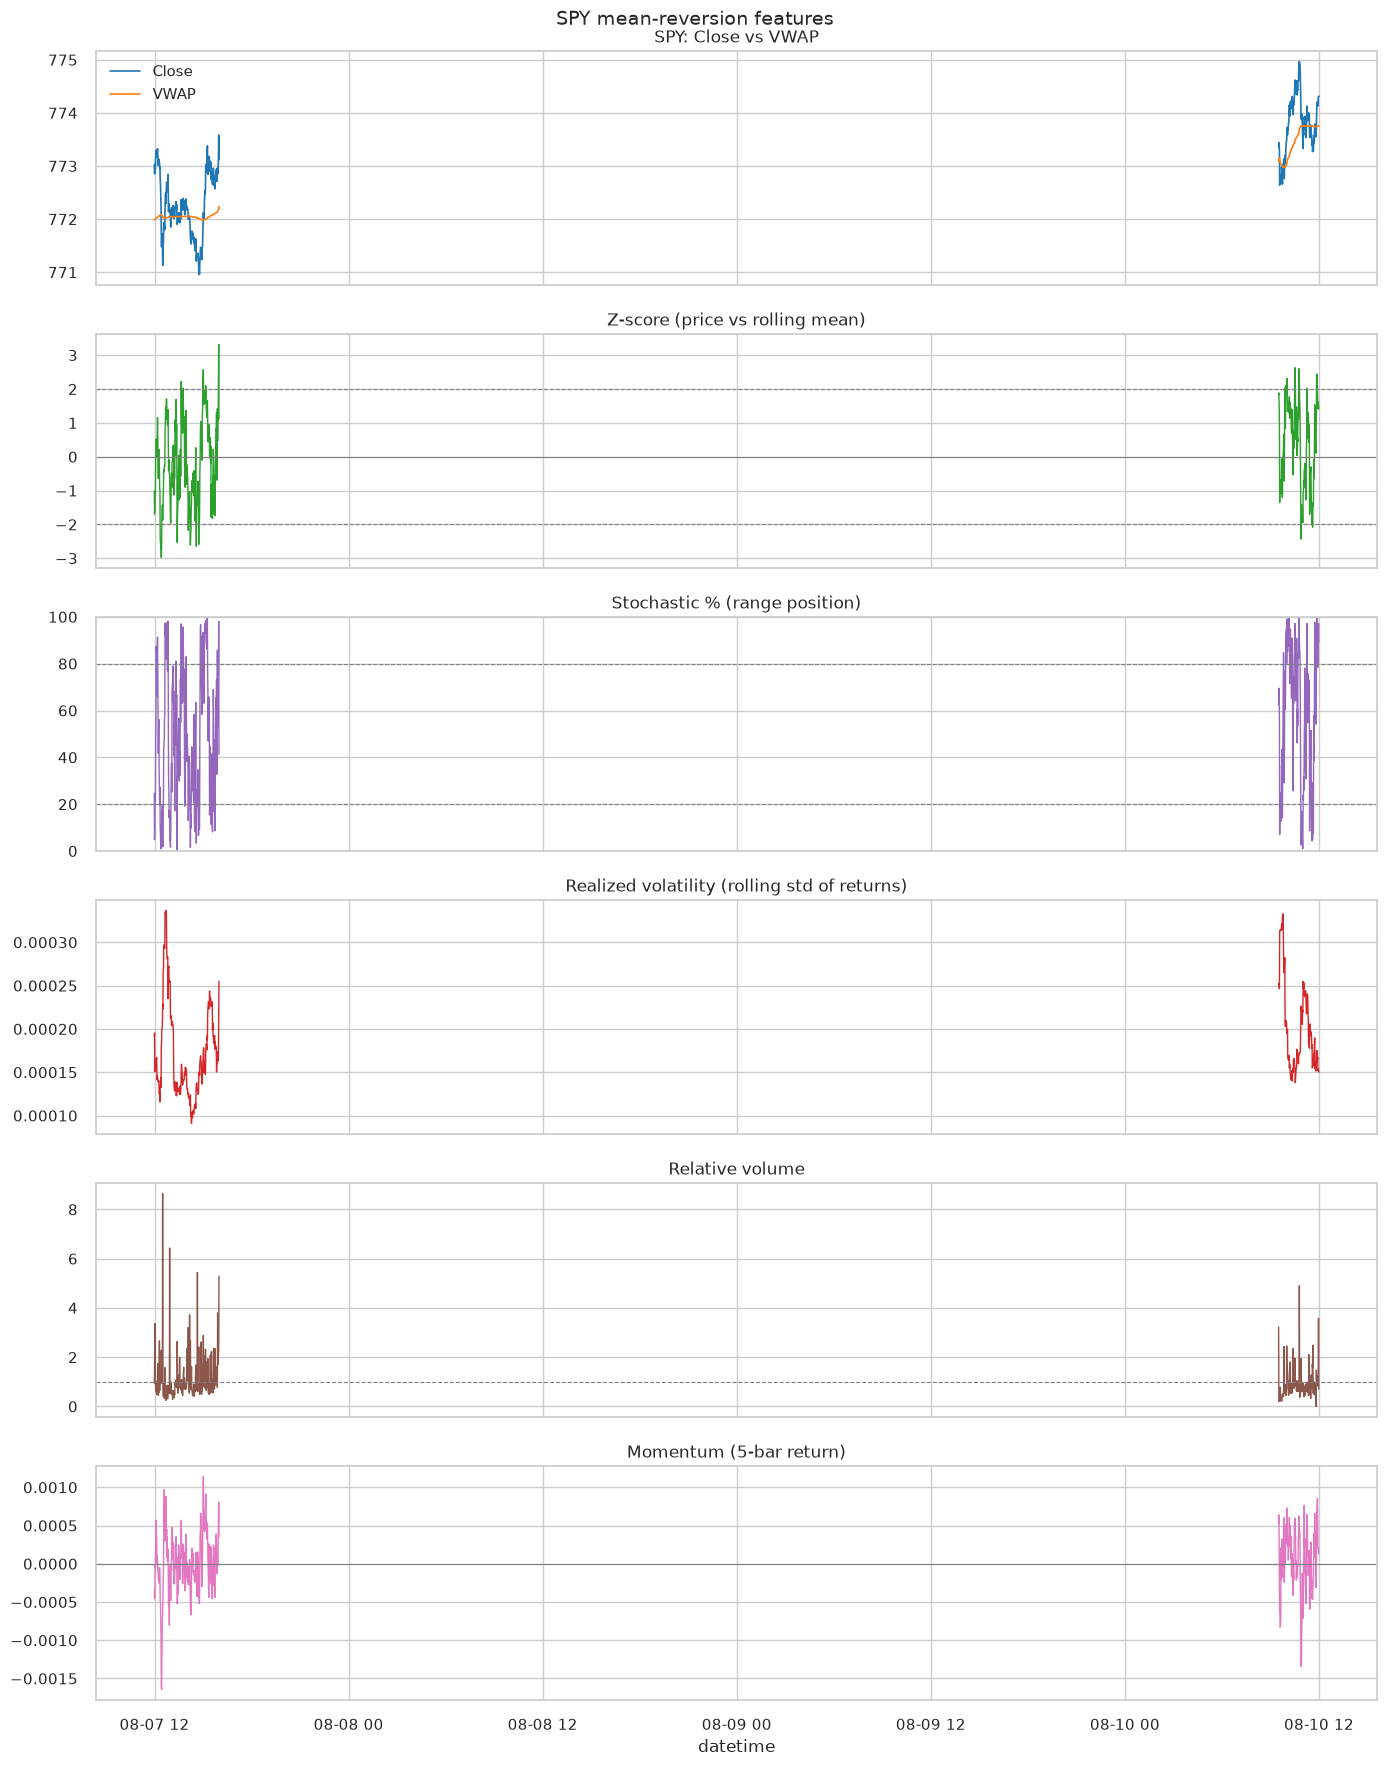

In [8]:
# Last few sessions only -- full history is too dense to read in one figure
recent = spy[spy.index >= spy.index.max() - pd.Timedelta("3D")]
plot_features(recent, "SPY")

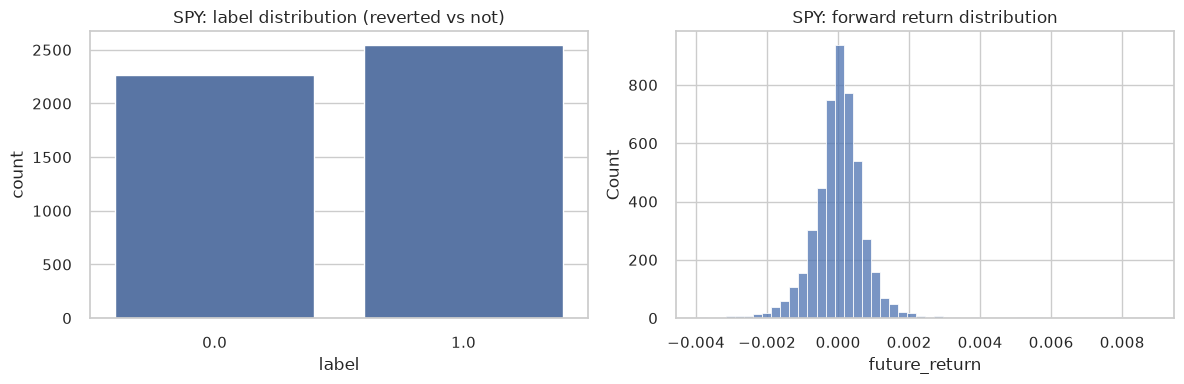

In [9]:
plot_label_distribution(spy, "SPY")

## ES=F (5m, near-24h future)

In [10]:
es = pd.read_csv(_intraday_path("ES=F", "5m"), index_col=0, parse_dates=True)
es = build_features(es)
es = make_labels(es)
print("shape:", es.shape)
print("label rate:", round(es["label"].mean(), 4))
es.tail()

shape: (14750, 24)
label rate: 0.5228


,Close,High,Low,Open,Volume,zscore,vwap,vwap_dist,stoch_pct,realized_vol,...,atr_pct,return_autocorr,bb_width,time_sin,time_cos,dist_from_open,dist_from_high,dist_from_low,future_return,label
datetime,,,,,,,,,,,,,,,,,,,,,
2026-08-10 11:05:00-04:00,7782.00,7786.75,7782.00,7783.50,8691,-0.318343,7782.669904,-0.000086,14.666667,0.000441,...,0.000718,-0.001410,0.000847,-0.387788,0.921749,-0.000193,-0.002052,0.001577,-0.000161,0.0
2026-08-10 11:10:00-04:00,7784.75,7785.75,7780.75,7782.00,7709,0.008290,7782.692718,0.000264,29.333333,0.000445,...,0.000720,-0.021126,0.000775,-0.346636,0.938000,0.000161,-0.001699,0.001931,-0.000739,0.0
2026-08-10 11:15:00-04:00,7785.75,7788.50,7784.25,7784.75,9693,0.088088,7782.782592,0.000381,34.666667,0.000444,...,0.000716,-0.005640,0.000711,-0.304806,0.952415,0.000289,-0.001571,0.002059,-0.000161,0.0
2026-08-10 11:20:00-04:00,7785.75,7787.50,7784.50,7786.00,6415,-0.031765,7782.835350,0.000374,34.666667,0.000440,...,0.000706,0.031863,0.000606,-0.262379,0.964965,0.000289,-0.001571,0.002059,-0.000482,0.0
2026-08-10 11:25:00-04:00,7784.25,7786.00,7780.75,7785.75,7822,-0.460737,7782.852070,0.000180,26.666667,0.000428,...,0.000718,0.040363,0.000554,-0.219439,0.975626,0.000096,-0.001763,0.001866,0.000482,1.0


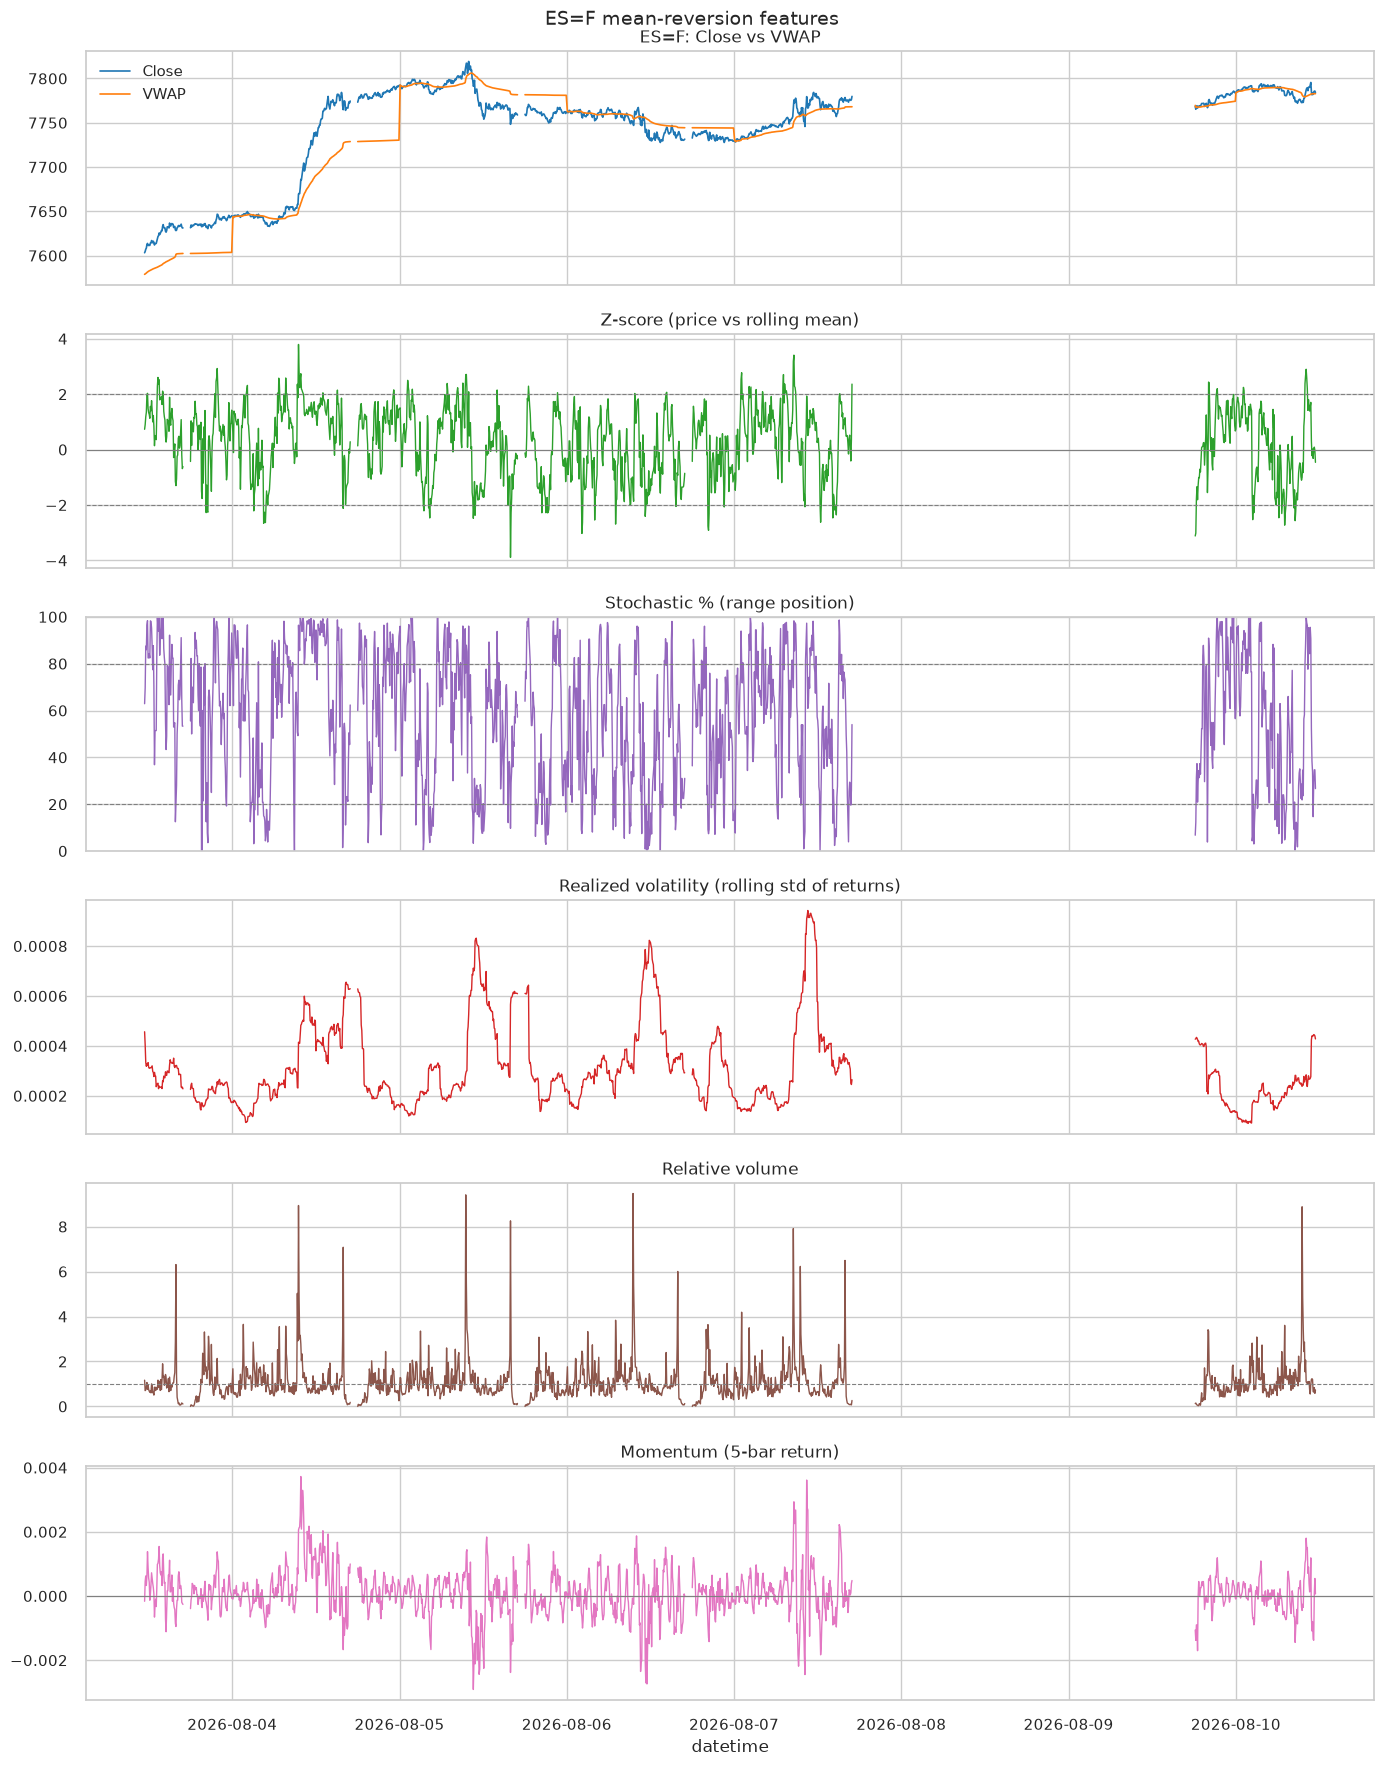

In [11]:
recent_es = es[es.index >= es.index.max() - pd.Timedelta("7D")]
plot_features(recent_es, "ES=F")

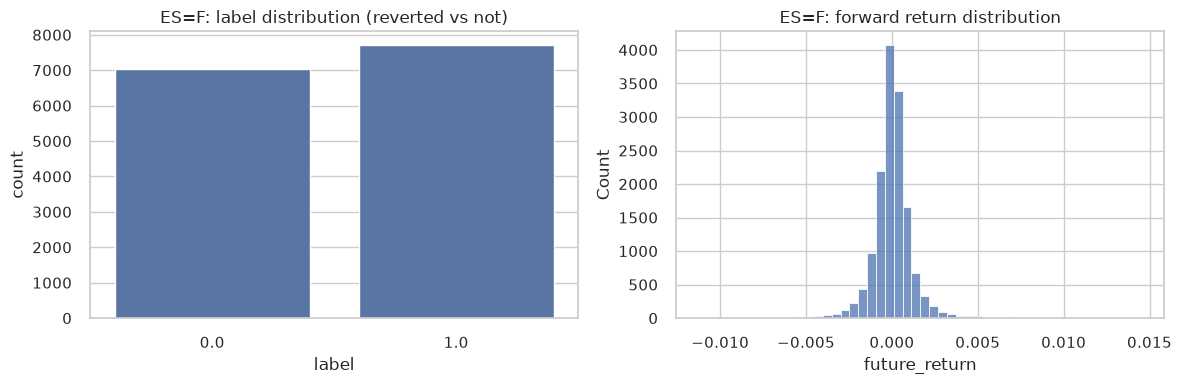

In [12]:
plot_label_distribution(es, "ES=F")

## Try new features here

Scratch space for experimenting with feature/window/label variants before promoting
anything back into a reusable module.

## Feature screening: which features carry the most signal?

Univariate AUC of each feature against the reversion label -- crude, but a fast, honest
way to answer "does this feature help at all" before investing in a real model/backtest.
Symmetric features (can be predictive via magnitude in either direction, e.g. zscore,
momentum) are scored via `abs()`; one-directional features are scored raw. AUC of 0.5 =
no better than random; further from 0.5 (either side) = more signal. Not a substitute for
walk-forward validation -- univariate signal doesn't guarantee it survives in a real model,
and this says nothing about P&L (no trade mechanics/cost model exists yet).

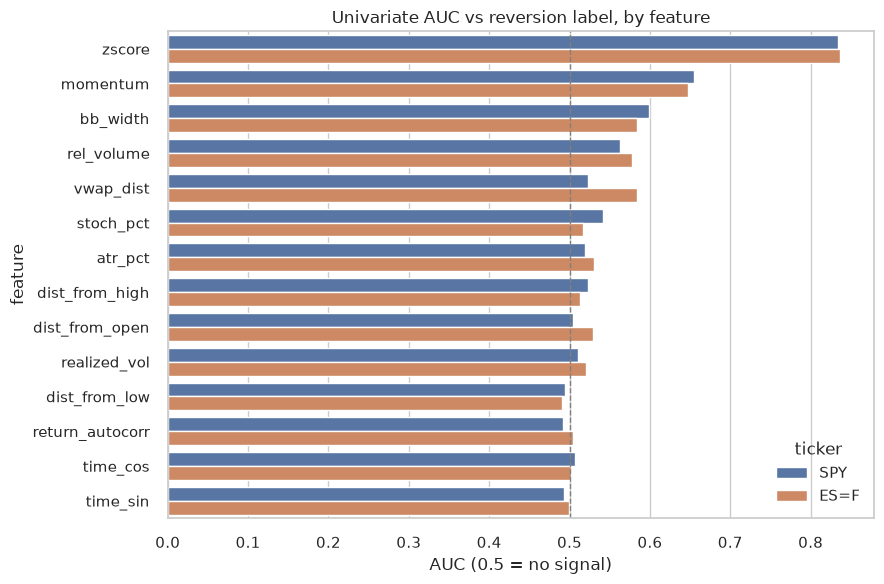

ticker,ES=F,SPY
feature,,
zscore,0.836942,0.834119
momentum,0.647700,0.654823
bb_width,0.583422,0.598258
rel_volume,0.577352,0.563292
vwap_dist,0.583926,0.522733
stoch_pct,0.517110,0.541512
atr_pct,0.530815,0.519570
dist_from_high,0.512590,0.523504
dist_from_open,0.529503,0.504245


In [13]:
from sklearn.metrics import roc_auc_score

# Symmetric features: predictive power likely comes from magnitude, not sign.
SYMMETRIC_FEATURES = {
    "zscore", "vwap_dist", "momentum", "return_autocorr",
    "time_sin", "time_cos", "dist_from_open",
}
ALL_FEATURES = [
    "zscore", "vwap_dist", "stoch_pct", "realized_vol", "rel_volume", "momentum",
    "atr_pct", "return_autocorr", "bb_width", "time_sin", "time_cos",
    "dist_from_open", "dist_from_high", "dist_from_low",
]


def screen_features(df: pd.DataFrame, ticker: str) -> pd.DataFrame:
    rows = []
    for col in ALL_FEATURES:
        values = df[col].abs() if col in SYMMETRIC_FEATURES else df[col]
        auc = roc_auc_score(df["label"], values)
        rows.append({"ticker": ticker, "feature": col, "auc": auc, "abs_edge": abs(auc - 0.5)})
    return pd.DataFrame(rows).sort_values("abs_edge", ascending=False)


spy_screen = screen_features(spy, "SPY")
es_screen = screen_features(es, "ES=F")
combined = pd.concat([spy_screen, es_screen])

fig, ax = plt.subplots(figsize=(9, 6))
order = combined.groupby("feature")["abs_edge"].mean().sort_values(ascending=False).index
sns.barplot(data=combined, y="feature", x="auc", hue="ticker", order=order, ax=ax)
ax.axvline(0.5, color="gray", linewidth=1.0, linestyle="--", label="no signal (0.5)")
ax.set_title("Univariate AUC vs reversion label, by feature")
ax.set_xlabel("AUC (0.5 = no signal)")
fig.tight_layout()
plt.show()

combined.pivot(index="feature", columns="ticker", values="auc").reindex(order)

**Caveat on `zscore`'s AUC (~0.83-0.84, far above everything else):** treat this with
suspicion, not excitement. The label is defined as "did `|zscore|` shrink" -- so a large
`|zscore|` predicting a shrink is partly mechanical/near-tautological (regression to the
mean is baked into how the label was constructed from this same feature), not necessarily
real tradeable edge. `momentum` (~0.65) is the more informative result precisely because
it's *not* derived from the label's own construction. Don't read the ranking at face value
without accounting for this before deciding what's "best."

## Re-screening against the non-circular return-based label

Same univariate AUC screen, but using `make_return_labels()` instead of `make_labels()` --
label is realized forward price movement in the reversion direction, not zscore-shrinkage.
This is the honest version of "which features are best."

SPY label rate: 0.4684
ES=F label rate: 0.4908


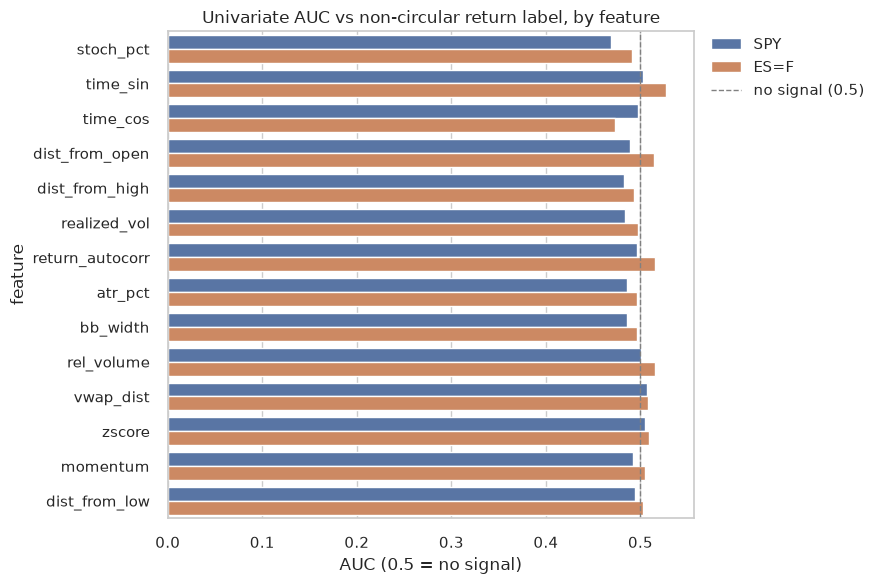

ticker,ES=F,SPY
feature,,
stoch_pct,0.490547,0.469076
time_sin,0.526674,0.502151
time_cos,0.473336,0.497870
dist_from_open,0.514016,0.488579
dist_from_high,0.493353,0.482060
realized_vol,0.497038,0.483551
return_autocorr,0.515482,0.496531
atr_pct,0.496425,0.485920
bb_width,0.496754,0.486165


In [14]:
spy_feat = build_features(pd.read_csv(_intraday_path("SPY", "1m"), index_col=0, parse_dates=True))
es_feat = build_features(pd.read_csv(_intraday_path("ES=F", "5m"), index_col=0, parse_dates=True))

spy_ret = make_return_labels(spy_feat)
es_ret = make_return_labels(es_feat)
print("SPY label rate:", round(spy_ret["label"].mean(), 4))
print("ES=F label rate:", round(es_ret["label"].mean(), 4))

spy_ret_screen = screen_features(spy_ret, "SPY")
es_ret_screen = screen_features(es_ret, "ES=F")
combined_ret = pd.concat([spy_ret_screen, es_ret_screen])

fig, ax = plt.subplots(figsize=(9, 6))
order_ret = combined_ret.groupby("feature")["abs_edge"].mean().sort_values(ascending=False).index
sns.barplot(data=combined_ret, y="feature", x="auc", hue="ticker", order=order_ret, ax=ax)
ax.axvline(0.5, color="gray", linewidth=1.0, linestyle="--", label="no signal (0.5)")
ax.set_title("Univariate AUC vs non-circular return label, by feature")
ax.set_xlabel("AUC (0.5 = no signal)")
ax.set_xlim(0, max(0.55, combined_ret["auc"].max() + 0.03))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
fig.tight_layout()
plt.show()

combined_ret.pivot(index="feature", columns="ticker", values="auc").reindex(order_ret)

## Horizon / threshold sweep

Is the null result specific to `horizon=5, threshold_return=0.0`, or does it hold across
the choices? For each (horizon, threshold) combo, label with `make_return_labels()` and
take the *best* feature's `|AUC-0.5|` -- i.e. "even picking the best-looking feature in
hindsight, how far from random can we get." A magnitude/sequential heatmap, not diverging
-- this is "how much edge," never negative.

**Multiple-testing caveat**: this sweep tests ~40+ label configs, each against 14
features. Any single cell that looks good is more likely to be noise from the sheer
number of things tried than genuine, robust signal -- treat a standout cell as a
hypothesis to re-verify (different date range, different ticker, held-out data), not
a discovery to act on.

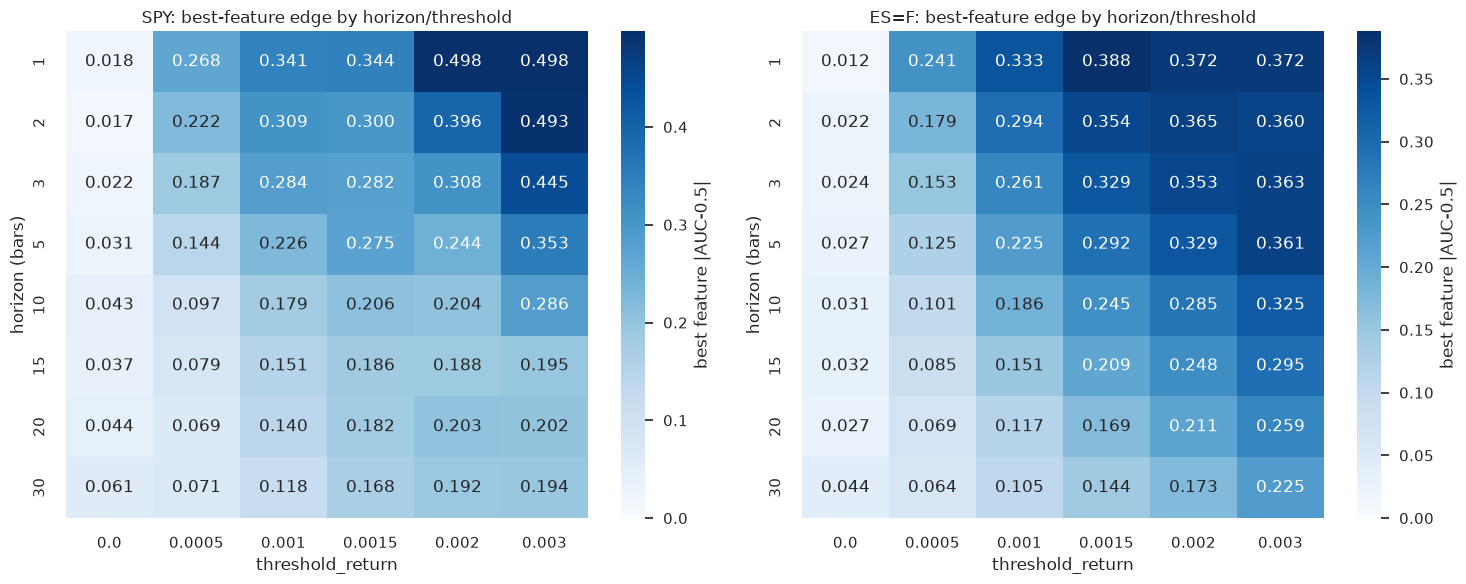

SPY best cell: horizon=1, threshold=0.002, feature=time_cos, auc=0.9978, label_rate=0.001, n=4814
ES=F best cell: horizon=1, threshold=0.0015, feature=atr_pct, auc=0.8879, label_rate=0.011, n=14754


In [15]:
HORIZONS = [1, 2, 3, 5, 10, 15, 20, 30]
THRESHOLDS = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.003]


def sweep_labels(df_feat: pd.DataFrame, ticker: str) -> pd.DataFrame:
    rows = []
    for horizon in HORIZONS:
        for threshold in THRESHOLDS:
            labeled = make_return_labels(df_feat, horizon=horizon, threshold_return=threshold)
            if labeled["label"].nunique() < 2 or len(labeled) < 50:
                continue
            screen = screen_features(labeled, ticker)
            best = screen.loc[screen["abs_edge"].idxmax()]
            rows.append({
                "ticker": ticker, "horizon": horizon, "threshold": threshold,
                "best_feature": best["feature"], "best_auc": best["auc"],
                "best_edge": best["abs_edge"], "label_rate": labeled["label"].mean(),
                "n": len(labeled),
            })
    return pd.DataFrame(rows)


spy_sweep = sweep_labels(spy_feat, "SPY")
es_sweep = sweep_labels(es_feat, "ES=F")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, sweep, ticker in zip(axes, [spy_sweep, es_sweep], ["SPY", "ES=F"]):
    pivot = sweep.pivot(index="horizon", columns="threshold", values="best_edge")
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues", vmin=0, ax=ax,
                cbar_kws={"label": "best feature |AUC-0.5|"})
    ax.set_title(f"{ticker}: best-feature edge by horizon/threshold")
    ax.set_xlabel("threshold_return")
    ax.set_ylabel("horizon (bars)")
fig.tight_layout()
plt.show()

for sweep, ticker in [(spy_sweep, "SPY"), (es_sweep, "ES=F")]:
    top = sweep.loc[sweep["best_edge"].idxmax()]
    print(
        f"{ticker} best cell: horizon={top['horizon']}, threshold={top['threshold']}, "
        f"feature={top['best_feature']}, auc={top['best_auc']:.4f}, "
        f"label_rate={top['label_rate']:.3f}, n={top['n']}"
    )

**The "hot corner" (low horizon, high threshold) is not real signal — read it as a
warning, not a discovery.** The best cells found: SPY `horizon=1, threshold=0.002` hits
AUC=0.998, but at `label_rate=0.001` on `n=4814` — **~5 positive examples total.** ES=F's
best cell (`horizon=1, threshold=0.0015`, AUC=0.888) has `label_rate=0.011` on `n=14754`
— ~162 positives, still a small, heavily imbalanced minority class. AUC is unreliable
with that few positive examples: a handful of extreme rows can trivially "separate"
from the majority on almost any feature by chance, especially after testing ~40 label
configs × 14 features (the multiple-testing problem flagged above, now visibly realized).

The heatmap's overall *shape* — edge growing smoothly as threshold rises and horizon
shrinks — is exactly what shrinking sample size predicts on its own, independent of any
real predictability, so the gradient itself isn't evidence of an exploitable pattern.
**The original null result at `horizon=5, threshold=0.0` (a well-populated, roughly
balanced label) remains the trustworthy read: no real signal found in this feature set.**